# Leave-One-Out Link Ratios with GridSearch

In [1]:
import numpy as np
import pandas as pd

import chainladder as cl

`Development(drop=(origin, age))` leaves one link ratio out of the average.
Dropping each observed ratio in turn and refitting shows which ratios move
the selected factors and the reserve the most. Verdonck and Debruyne show
that the influence of a single cell on the chain-ladder estimates is
unbounded {cite}`verdonck2011`, so a large move here marks a ratio worth a
closer look.

`GridSearch` already refits an estimator once per parameter value. The only
new code is a helper that builds the parameter grid. It returns `None` for
the base fit and one `(origin, age)` pair for every observed link ratio,
including ages that have only one ratio.

In [2]:
def leave_one_out_grid(triangle, step="dev"):
    link_ratio = triangle.link_ratio
    observed = ~np.isnan(link_ratio.values[0, 0])
    cells = [None]
    for i, j in zip(*np.nonzero(observed)):
        origin = str(link_ratio.origin[i].year)
        age = int(link_ratio.development[j].split("-")[0])
        cells.append((origin, age))
    return {f"{step}__drop": cells}


raa = cl.load_sample("raa")
raa_grid = leave_one_out_grid(raa)
raa_grid["dev__drop"][:4]

[None, ('1981', 12), ('1981', 24), ('1981', 36)]

The grid key `dev__drop` sends each value to the `drop` parameter of the
step named `dev` in a `Pipeline`. One scoring callable returns total IBNR
and the other returns the full `ldf_` array of the refit.

In [3]:
pipe = cl.Pipeline([("dev", cl.Development()), ("model", cl.Chainladder())])
scoring = {
    "ibnr": lambda model: float(model.named_steps.model.ibnr_.sum()),
    "ldf": lambda model: model.named_steps.dev.ldf_.values[0, 0, 0],
}
raa_results = cl.GridSearch(pipe, raa_grid, scoring).fit(raa).results_
len(raa_results)

46

That is the base fit plus 45 refits, one for each link ratio in the 10 by 10
triangle. The next function turns `results_` into one row per dropped ratio.
It records the ratio itself, the factor at that age before and after the
drop, and the change in total IBNR. Rows run from the largest move to the
smallest.

In [4]:
def summarize(results, triangle):
    link_ratio = triangle.link_ratio
    ages = [int(interval.split("-")[0]) for interval in link_ratio.development]
    origins = [str(origin.year) for origin in link_ratio.origin]
    base = results[results["dev__drop"].isna()].iloc[0]
    rows = []
    for _, row in results[results["dev__drop"].notna()].iterrows():
        origin, age = row["dev__drop"]
        i, j = origins.index(origin), ages.index(age)
        change = row["ibnr"] - base["ibnr"]
        rows.append({
            "origin": origin,
            "age": age,
            "link ratio": link_ratio.values[0, 0, i, j],
            "ldf before": base["ldf"][j],
            "ldf after": row["ldf"][j],
            "IBNR change": change,
            "share of IBNR": change / base["ibnr"],
        })
    table = pd.DataFrame(rows)
    order = table["IBNR change"].abs().sort_values(ascending=False).index
    return table.loc[order].reset_index(drop=True)


formats = {
    "link ratio": "{:.4f}",
    "ldf before": "{:.4f}",
    "ldf after": "{:.4f}",
    "IBNR change": "{:,.0f}",
    "share of IBNR": "{:.1%}",
}
raa_table = summarize(raa_results, raa)
raa_table.head(5).style.format(formats, na_rep="NaN").hide(axis="index")

origin,age,link ratio,ldf before,ldf after,IBNR change,share of IBNR
1985,60,1.0087,1.1134,1.1525,"3,363",6.5%
1981,96,1.0029,1.0169,1.0331,"2,818",5.4%
1981,12,1.6498,2.9994,3.4016,"2,468",4.7%
1982,96,1.0331,1.0169,1.0029,"-2,449",-4.7%
1982,36,1.9766,1.2709,1.2227,"-2,217",-4.3%


On `raa`, base IBNR is 52,135 and no single ratio moves it by more than
6.5%. Two of the 45 ratios move it by more than 5%. The largest move comes
from 1985 at 60, an ordinary looking ratio of 1.0087. It is one of only five
ratios at 60-72, so dropping it raises that factor from 1.1134 to 1.1525 and
IBNR by 3,363.

In [5]:
genins = cl.load_sample("genins")
genins_results = (
    cl.GridSearch(pipe, leave_one_out_grid(genins), scoring).fit(genins).results_
)
genins_table = summarize(genins_results, genins)
genins_table.head(5).style.format(formats, na_rep="NaN").hide(axis="index")

origin,age,link ratio,ldf before,ldf after,IBNR change,share of IBNR
2001,108,1.0177,1.0177,NaN,"-855,780",-4.6%
2002,96,1.0865,1.0766,1.0630,"-549,914",-2.9%
2004,36,1.7118,1.4574,1.4140,"-518,565",-2.8%
2004,48,1.0725,1.1739,1.1998,"509,117",2.7%
2003,60,1.0369,1.1038,1.1229,"487,330",2.6%


On `genins`, base IBNR is 18,680,856. The largest move comes from 2001 at
108, and its `ldf after` reads NaN. Both sample triangles have a single
ratio at 108-120, so dropping it leaves nothing to average:

In [6]:
dropped = cl.Development(drop=("2001", 108)).fit(genins)
pd.DataFrame(
    {
        "ldf_": dropped.ldf_.values[0, 0, 0, -2:],
        "cdf_": dropped.cdf_.values[0, 0, 0, -2:],
    },
    index=pd.Index([96, 108], name="age"),
)

,ldf_,cdf_
age,,
96,1.076555,1.076555
108,NaN,1.000000


With no ratio left, `ldf_` at 108 is NaN while `cdf_` at 108 is 1, so
`Chainladder` treats the missing factor as 1 and raises no warning. That row
measures the effect of setting the last factor to 1, which is a different
question from leaving out one ratio among several. The `raa` grid has the
same row at 1981 at 108, where IBNR falls by 1,774, or 3.4%. Among the
ratios that leave a factor behind, the largest move on `genins` comes from
2002 at 96, at -549,914 or -2.9%.

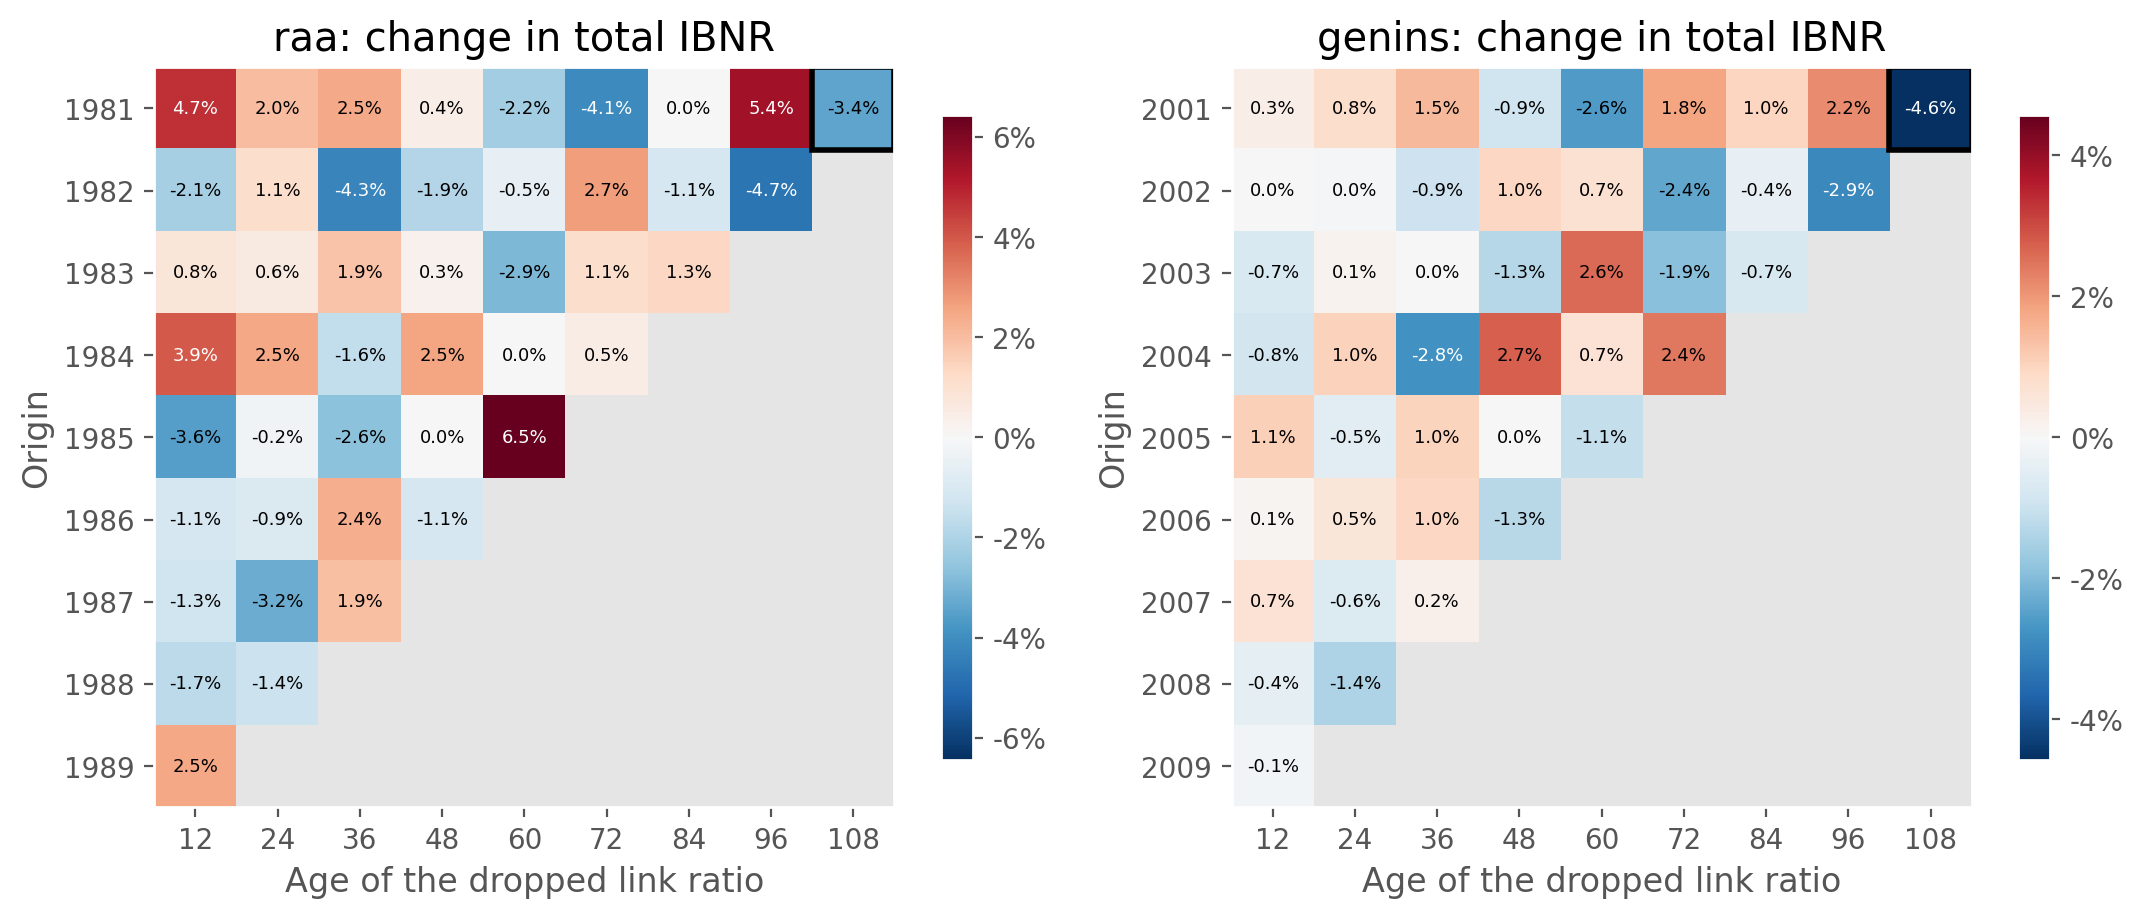

In [7]:
import matplotlib.pyplot as plt

plt.style.use("ggplot")
%config InlineBackend.figure_format = 'retina'

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (name, table) in zip(axes, {"raa": raa_table, "genins": genins_table}.items()):
    shares = table.pivot(index="origin", columns="age", values="share of IBNR")
    limit = np.abs(shares.values[np.isfinite(shares.values)]).max()
    image = ax.imshow(shares.values, cmap="RdBu_r", vmin=-limit, vmax=limit)
    for (i, j), value in np.ndenumerate(shares.values):
        if np.isfinite(value):
            label = f"{value:.1%}".replace("-0.0%", "0.0%")
            color = "white" if abs(value) > 0.6 * limit else "black"
            ax.text(j, i, label, ha="center", va="center", fontsize=6.5, color=color)
    single = table[table["ldf after"].isna()]
    for origin, age in zip(single["origin"], single["age"]):
        i, j = list(shares.index).index(origin), list(shares.columns).index(age)
        ax.add_patch(
            plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="black", lw=2)
        )
    ax.set_xticks(range(len(shares.columns)), shares.columns)
    ax.set_yticks(range(len(shares.index)), shares.index)
    ax.set_xlabel("Age of the dropped link ratio")
    ax.set_ylabel("Origin")
    ax.set_title(f"{name}: change in total IBNR")
    ax.grid(False)
    fig.colorbar(image, ax=ax, format=lambda x, _: f"{x:.0%}", shrink=0.8)
fig.tight_layout()

Each cell shows the change in total IBNR when that link ratio is left out,
and a black box marks the single-ratio cells. On `raa`, 20 of the 45 refits
move IBNR by more than 2%, against 9 of 45 on `genins`. To use the helper
with a pipeline that names its `Development` step differently, pass that
name as `step`. More scoring callables record more outputs, such as IBNR by
origin.